<a href="https://colab.research.google.com/github/Dexter0013/Tiny-ML-Case-Study/blob/main/Model/EdgeAI_Setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Preprocessing

In [2]:
import pandas as pd
import numpy as np
import time
import psutil
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# --- STEP 1: Load Dataset ---
# Ensure 'network_telemetry (1).csv' is uploaded to your Colab session storage
df = pd.read_csv('network_telemetry (1).csv')
print(f"Dataset Loaded Successfully. Shape: {df.shape}")

# --- STEP 2: Separate Features and Target ---
# 'label' is the target (0 for normal, 1 for DDoS attack)
# 'timestamp' is a unique time identifier and dropped to prevent overfitting
X = df.drop(columns=['label', 'timestamp'])
y = df['label']

# --- STEP 3: Encode Categorical Features ---
# Convert MAC address strings into numeric integer representations
for col in ['mac_src', 'mac_dst']:
    if col in X.columns:
        X[col] = LabelEncoder().fit_transform(X[col])

# --- STEP 4: Train-Test Split ---
# Split into 80% training and 20% testing sets, keeping class distributions balanced (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- STEP 5: Feature Scaling ---
# Normalize features so distance-based (SVM) and probabilistic (Naive Bayes) models perform stably
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing complete! Data ready for training.")

Dataset Loaded Successfully. Shape: (74, 9)
Preprocessing complete! Data ready for training.


2. Model Accuracy

In [5]:
# --- Define Models ---
models = {
    'Decision Tree (DT)': DecisionTreeClassifier(random_state=42),
    'Naive Bayes (NB)': GaussianNB(),
    'Support Vector Machine (SVM)': SVC(kernel='rbf', C=1.0, random_state=42)
}

accuracy_results = {}

print("\n" + "="*40)
print("          INDIVIDUAL MODEL ACCURACY         ")
print("="*40)

for name, model in models.items():
    X_tr = X_train if 'Decision Tree' in name else X_train_scaled
    X_te = X_test if 'Decision Tree' in name else X_test_scaled

    # Train and Predict
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    # Calculate Accuracy
    acc = accuracy_score(y_test, y_pred) * 100
    accuracy_results[name] = acc

    # Print Accuracy Separately
    print(f"• {name}: {acc:.2f}%")

print("="*40)


          INDIVIDUAL MODEL ACCURACY         
• Decision Tree (DT): 100.00%
• Naive Bayes (NB): 100.00%
• Support Vector Machine (SVM): 100.00%


3. Result and Display


             DETAILED PERFORMANCE METRICS TABLE           
                       Model  Accuracy (%)  Precision  Recall  F1-Score  Inference Time (s)
          Decision Tree (DT)         100.0        1.0     1.0       1.0             0.00290
            Naive Bayes (NB)         100.0        1.0     1.0       1.0             0.00037
Support Vector Machine (SVM)         100.0        1.0     1.0       1.0             0.00051


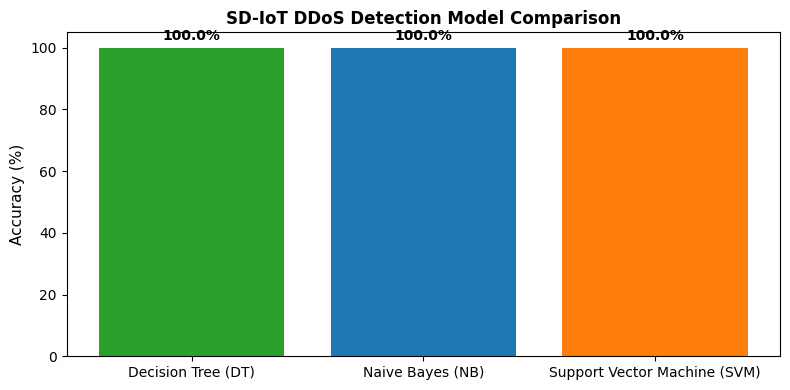

In [6]:
results = []

for name, model in models.items():
    X_tr = X_train if 'Decision Tree' in name else X_train_scaled
    X_te = X_test if 'Decision Tree' in name else X_test_scaled

    start_time = time.time()
    y_pred = model.predict(X_te)
    elapsed_time = time.time() - start_time

    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_results[name], 2),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'Inference Time (s)': round(elapsed_time, 5)
    })

# --- Display Detailed Results Table ---
results_df = pd.DataFrame(results)
print("\n" + "="*60)
print("             DETAILED PERFORMANCE METRICS TABLE           ")
print("="*60)
print(results_df.to_string(index=False))
print("="*60)

# --- Display Visual Chart ---
plt.figure(figsize=(8, 4))
bars = plt.bar(results_df['Model'], results_df['Accuracy (%)'], color=['#2ca02c', '#1f77b4', '#ff7f0e'])
plt.ylabel('Accuracy (%)', fontsize=11)
plt.title('SD-IoT DDoS Detection Model Comparison', fontsize=12, fontweight='bold')
plt.ylim(0, 105)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1.5, f"{height}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

3. Comparison Table

In [7]:
import pandas as pd
from IPython.display import display, Markdown

# Define the comparison data
comparison_data = {
    "Feature / Metric": [
        "Processor & Clock",
        "Hardware FPU",
        "SRAM Memory",
        "Flash Memory",
        "Decision Tree (DT)",
        "Naive Bayes (NB)",
        "Support Vector Machine (SVM)",
        "Network Connectivity",
        "Best Deployment Approach"
    ],
    "ESP32 (Xtensa Dual-Core)": [
        "Dual-core Tensilica LX6 @ 240 MHz",
        "Yes (Native hardware floating-point support)",
        "512 KB",
        "4 MB to 16 MB",
        "Extremely Fast (~2–4 µs)\n• Converts to lightweight C if/else logic.\n• Near-zero RAM footprint (< 5 KB).",
        "Very Fast (~5–10 µs)\n• Handles Gaussian calculations quickly with the built-in FPU.",
        "Moderate (~1–3 ms)\n• Benefits from hardware FPU when evaluating RBF kernel distances.",
        "Built-in Wi-Fi & Bluetooth (ESP32 / ESP32-S3)\n• Ideal for inline wireless telemetry and SDN node forwarding.",
        "C/C++ (emlearn via Arduino IDE or ESP-IDF)\n• Best for high-frequency packet processing and native Wi-Fi integration."
    ],
    "Raspberry Pi Pico / Pico W (RP2040)": [
        "Dual-core ARM Cortex-M0+ @ 133 MHz",
        "No (Software-emulated floating-point)",
        "264 KB",
        "2 MB (expandable on custom boards)",
        "Extremely Fast (~3–6 µs)\n• Executes conditional branching effortlessly.\n• Minimal memory footprint (< 5 KB).",
        "Fast (~10–20 µs)\n• Arithmetic calculations run smoothly via software emulation.",
        "Slower (~3–8 ms)\n• Lacks a hardware FPU, making heavy distance kernels slightly slower.",
        "Wi-Fi Available on Pico W\n• Standard Pico requires external modules (e.g., W5500) for network connectivity.",
        "MicroPython or C/C++ (Pico SDK)\n• Great for lightweight, low-power sensor edge logging."
    ]
}

# Create DataFrame
df_comparison = pd.DataFrame(comparison_data)

# Style and display the table in Colab
display(Markdown("### 📊 Hardware & Model Compatibility: ESP32 vs. Raspberry Pi Pico"))
display(df_comparison.style.set_properties(**{
    'text-align': 'left',
    'vertical-align': 'top',
    'white-space': 'pre-wrap'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'center'), ('background-color', '#f0f0f0'), ('font-weight', 'bold')]}
]))

### 📊 Hardware & Model Compatibility: ESP32 vs. Raspberry Pi Pico

,Feature / Metric,ESP32 (Xtensa Dual-Core),Raspberry Pi Pico / Pico W (RP2040)
0,Processor & Clock,Dual-core Tensilica LX6 @ 240 MHz,Dual-core ARM Cortex-M0+ @ 133 MHz
1,Hardware FPU,Yes (Native hardware floating-point support),No (Software-emulated floating-point)
2,SRAM Memory,512 KB,264 KB
3,Flash Memory,4 MB to 16 MB,2 MB (expandable on custom boards)
4,Decision Tree (DT),Extremely Fast (~2–4 µs) • Converts to lightweight C if/else logic. • Near-zero RAM footprint (< 5 KB).,Extremely Fast (~3–6 µs) • Executes conditional branching effortlessly. • Minimal memory footprint (< 5 KB).
5,Naive Bayes (NB),Very Fast (~5–10 µs) • Handles Gaussian calculations quickly with the built-in FPU.,Fast (~10–20 µs) • Arithmetic calculations run smoothly via software emulation.
6,Support Vector Machine (SVM),Moderate (~1–3 ms) • Benefits from hardware FPU when evaluating RBF kernel distances.,"Slower (~3–8 ms) • Lacks a hardware FPU, making heavy distance kernels slightly slower."
7,Network Connectivity,Built-in Wi-Fi & Bluetooth (ESP32 / ESP32-S3) • Ideal for inline wireless telemetry and SDN node forwarding.,"Wi-Fi Available on Pico W • Standard Pico requires external modules (e.g., W5500) for network connectivity."
8,Best Deployment Approach,C/C++ (emlearn via Arduino IDE or ESP-IDF) • Best for high-frequency packet processing and native Wi-Fi integration.,"MicroPython or C/C++ (Pico SDK) • Great for lightweight, low-power sensor edge logging."
